# Python API example

Loads the model + link table produced by a genome-wide, batch-corrected `run_genomewide.sh` run (multiDGD training + gene2peak perturbation over all genes; a multi-hour GPU job) and visualizes them — no retraining. Set the paths below to your `run_genomewide.sh` output. The heavy train/perturbation steps appear as commented reference cells with rough timings.


In [1]:
from multidgd_e2g import io, MultiDGDAdapter, compute_cell_deltas
import pandas as pd, numpy as np

# --- edit these to your run_genomewide.sh output (genome-wide, batch-corrected) ---
EXPORT_DIR = "path/to/genomewide_export"
MODEL_DIR  = "path/to/run/model"
MODEL_NAME = "dgd_cd14_e2g"
LINKS      = "path/to/run/links.tsv"
GTF        = "path/to/genes.gtf"   # gene models (GTF) for the locus/heatmap TSS


## Step 1 — Load the export

`read_export` rebuilds the AnnData the run trained on (genome-wide; the .mtx is large, so this takes a moment). `assign_train_val_split` reproduces the training split (seed 0) so the loaded per-cell representations line up.

In [2]:
adata, genes, peaks, pairs = io.read_export(EXPORT_DIR)
io.assign_train_val_split(adata)
print(f"{adata.n_obs} cells | {len(genes)} genes | {len(peaks)} peaks | {len(pairs)} candidate pairs")

5486 cells | 19624 genes | 108533 peaks | 697064 candidate pairs


## Step 2 — Load the trained model

Training is done by `run_genomewide.sh` (multi-hour GPU); here we load the saved checkpoint. `learn_test_representations` (a few minutes) is needed only for the per-cell heatmap in Step 8.

In [3]:
# --- produced by run_genomewide.sh (training ~hours on GPU); shown for reference ---
# model = MultiDGDAdapter.train(adata, MODEL_DIR + '/', MODEL_NAME, latent_dim=20,
#                               n_components=None, n_epochs=500)
model = MultiDGDAdapter.load(adata, MODEL_DIR.rstrip('/') + '/', MODEL_NAME)
model.learn_test_representations(adata, n_epochs=20)

Covariate model initialized as:

        Gaussian_mix_compture:
            Dimensionality: 2
            Number of components: 2
        


#######################
Training status
#######################
True


making potential reps
   all potential reps:  torch.Size([2, 22])
calculating losses for each new sample and potential reps


training selected reps for  20  epochs


Training: 100%|██████████| 20/20 [01:34<00:00,  4.75s/epochs, loss=0.293, reconstruction_loss=0.293]


## Model diagnostics

Optional. `plot_latent_space()` (latent PCA + GMM) loads from the checkpoint. `plot_history()` is only available right after training (multiDGD does not persist it) — see `run_genomewide.sh`.


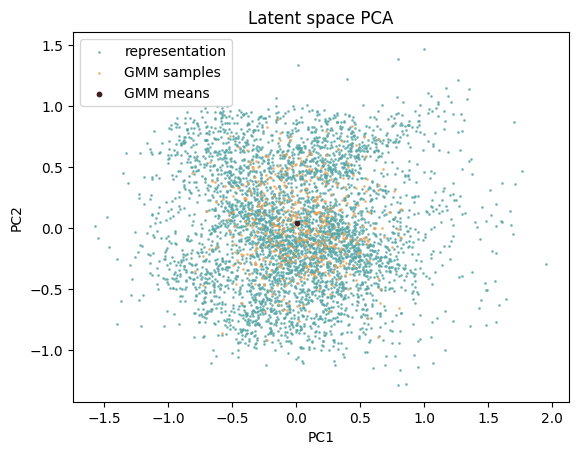

In [4]:
model.model.plot_latent_space()

### Covariate latent

`get_covariate_representation()` returns the correction latent; coloured by sample it shows the batch structure the model corrects for.


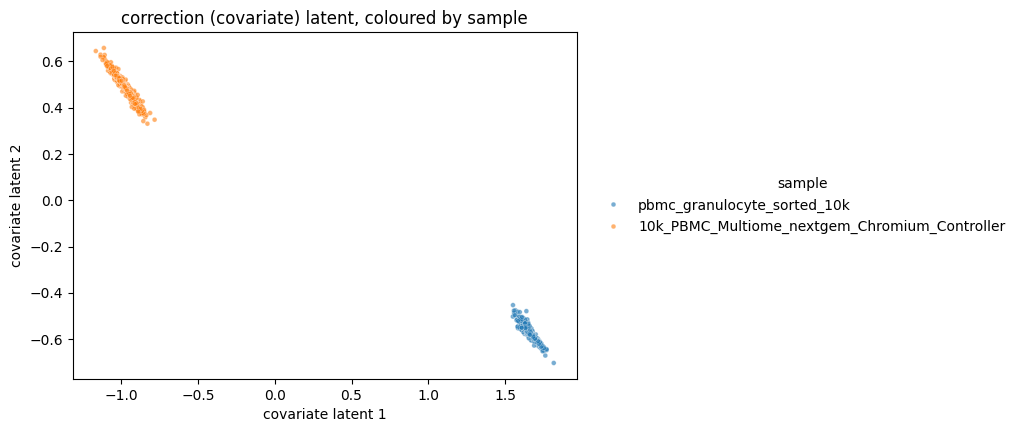

In [5]:
import seaborn as sns, matplotlib.pyplot as plt

cov = model.model.get_covariate_representation(split='train')
train_mask = adata.obs['train_val_test'].values == 'train'
sample = adata.obs.loc[train_mask, 'covariate_sample'].values

fig, ax = plt.subplots(figsize=(6.5, 4.5))
if cov.shape[1] >= 2:
    sns.scatterplot(x=cov[:, 0], y=cov[:, 1], hue=sample, s=12, alpha=0.6, ax=ax)
    ax.set_xlabel('covariate latent 1'); ax.set_ylabel('covariate latent 2')
else:
    y = np.random.default_rng(0).normal(0, 0.02, size=cov.shape[0])
    sns.scatterplot(x=cov[:, 0], y=y, hue=sample, s=12, alpha=0.6, ax=ax)
    ax.set_xlabel('covariate latent'); ax.set_yticks([])
ax.set_title('correction (covariate) latent, coloured by sample')
ax.legend(title='sample', frameon=False, loc='center left', bbox_to_anchor=(1.02, 0.5))
plt.show()


## Step 3 — Perturbation + scoring

The genome-wide perturbation over all genes and the scoring are the heavy GPU steps; `run_genomewide.sh` runs them and writes the link table we load in Step 4. Shown here as reference. `build_groups` (fast) is still run because Step 8's heatmap needs `silenced_index`.


In [6]:
gene_row = {g: i for i, g in enumerate(genes)}
peak_col = {p: i for i, p in enumerate(peaks)}
groups, silenced_index, resp_index = io.build_groups(pairs, gene_row, peak_col, 'gene2peak')

# --- heavy: produced by run_genomewide.sh (perturbation over all genes ~hours on GPU) ---
# from multidgd_e2g import compute_deltas, score_from_deltas, records_to_p2g
# D, kept, p0, resp_names = compute_deltas(model, groups, silenced_index, resp_index,
#                                          'gene2peak', cell_batch=8192)
# records = score_from_deltas(D, kept, p0, groups, resp_index, 'gene2peak', match_bg=True)  # accessibility-matched null (default)
# records_to_p2g(records).to_csv(LINKS, sep='\t', index=False)

## Step 4 — Load the link table

The table has fewer rows than the candidate pairs above — scoring skips genes expressed in fewer than 3 cells (~3.8k of the 19.6k genes here), so their pairs are dropped.


In [7]:
df = pd.read_csv(LINKS, sep='\t')     # fdr / twosided_fdr are already in the file
print(f'{len(df)} links loaded')
df.sort_values('score', ascending=False).head(10)


595594 links loaded


,peak,peak_chr,peak_start,peak_end,gene,score,delta,zscore,pvalue,fdr,twosided_pvalue,twosided_fdr,link_dir
437786,chr19-54189073-54191521,chr19,54189073,54191521,RPS9,20.776026,-1.336241e-05,9.451200,1.674842e-21,9.975261e-16,3.349685e-21,1.330035e-16,1
484044,chr6-87829849-87830048,chr6,87829849,87830048,SPACA1,13.800367,-1.679506e-07,7.591300,1.583554e-14,4.715775e-09,3.167107e-14,3.309316e-10,1
178377,chr1-159430723-159431427,chr1,159430723,159431427,FCER1A,12.587611,-2.484453e-07,7.220777,2.584574e-13,5.131190e-08,5.169149e-13,4.965668e-09,1
529664,chr2-151325453-151326257,chr2,151325453,151326257,TNFAIP6,12.029772,-3.018849e-07,7.044037,9.337442e-13,1.390331e-07,1.867488e-12,1.711177e-08,1
17305,chr7-17059752-17059997,chr7,17059752,17059997,AGR2,10.833720,-3.474794e-07,6.649897,1.466494e-11,1.746870e-06,2.932989e-11,2.298514e-07,1
356674,chr19-54189073-54191521,chr19,54189073,54191521,OSCAR,10.560049,-2.330231e-06,6.556519,2.753918e-11,2.726861e-06,5.507837e-11,4.205685e-07,1
18001,chr5-369149-369348,chr5,369149,369348,AHRR,10.494189,-4.269124e-07,6.533856,3.204872e-11,2.726861e-06,6.409744e-11,4.832411e-07,1
569527,chrX-73850720-73851880,chrX,73850720,73851880,XIST,10.404724,-1.079269e-06,6.502950,3.937999e-11,2.931811e-06,7.875999e-11,5.791232e-07,1
312886,chr22-27686334-27686822,chr22,27686334,27686822,MN1,10.170268,-2.014638e-07,6.421280,6.756660e-11,4.305367e-06,1.351332e-10,9.251094e-07,1
104102,chr12-106279870-106280408,chr12,106279870,106280408,CKAP4,10.140940,-3.156061e-07,6.410994,7.228694e-11,4.305367e-06,1.445739e-10,9.784924e-07,1


## Step 5 — Summary

Significant links by one-sided FDR, split by direction (`link_dir`: +1 activating / -1 repressive).


In [8]:
PTHR = 0.05
fsig = df['fdr'] < 0.1
print(f'one-sided: nominal p<0.05 = {int((df.pvalue<PTHR).sum()):6d}   FDR<0.1 = {int(fsig.sum()):6d}   '
      f'(FDR: +{int((fsig & (df.link_dir>0)).sum())} activating, -{int((fsig & (df.link_dir<0)).sum())} repressive)')
df[['pvalue', 'fdr']].describe().loc[['min', '50%', 'max']]


one-sided: nominal p<0.05 =  26049   FDR<0.1 =    533   (FDR: +533 activating, -0 repressive)


,pvalue,fdr
min,1.674842e-21,9.975261e-16
50%,4.875881e-01,9.642880e-01
max,1.000000e+00,1.000000e+00


## Step 6 — Volcano

One panel, one-sided (activating-tail) test: x = `delta` (negative = activating, positive = repressive), y = `-log10(p)` (continuous evidence, as in the locus view), colour = the `FDR<0.1` call. By construction only the negative-`delta` (activating) side can be significant here — the one-sided test excludes the positive-`delta` wing, which is mostly the **softmax-renormalisation artefact** (silencing a gene redistributes probability mass onto accessible peaks, pushing them up), not real repression. Note most significant points sit near `delta`≈0: significance is driven by the low-variance background null, not by effect size.



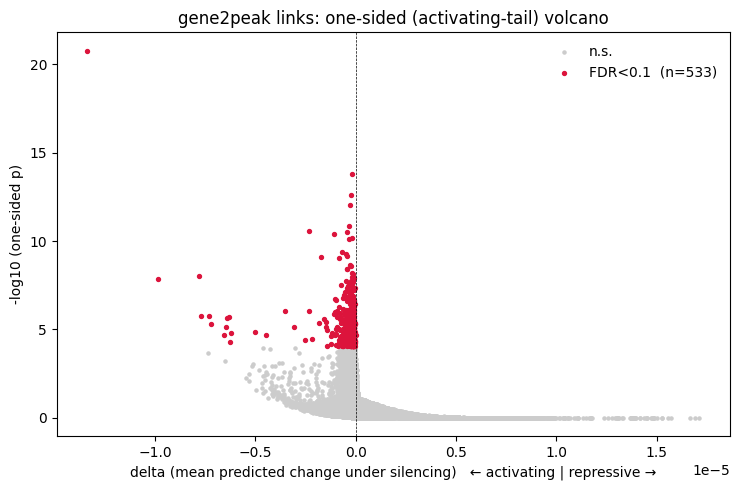

In [9]:
import numpy as np, matplotlib.pyplot as plt

sig = df['fdr'] < 0.1                                   # one-sided FDR = the significance call
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.scatter(df.loc[~sig, 'delta'], df.loc[~sig, 'score'], s=5, c='0.8',
           rasterized=True, label='n.s.')
ax.scatter(df.loc[sig, 'delta'],  df.loc[sig, 'score'],  s=8, c='crimson',
           rasterized=True, label=f'FDR<0.1  (n={int(sig.sum())})')
ax.axvline(0, color='k', lw=0.5, ls='--')
ax.set_xlabel('delta (mean predicted change under silencing)   \u2190 activating | repressive \u2192')
ax.set_ylabel('-log10 (one-sided p)')
ax.set_title('gene2peak links: one-sided (activating-tail) volcano')
ax.legend(frameon=False, loc='upper right')
plt.tight_layout(); plt.show()


## Effect vs distance to TSS

The raw perturbation effect `|delta|` is largest at the TSS and decays within ~2 kb — the accessibility/abundance bias that multiDGD itself reported it could not remove (Schuster et al. 2024, Supplementary Fig. 21). The accessibility-matched null (default) removes it: the association score `|z|` is **flat with distance**, so links are no longer dominated by promoters/high-accessibility peaks. Top: raw `|delta|`; bottom: matched-null `|z|` (rolling mean over 0–50 kb; dashed line at 2 kb).


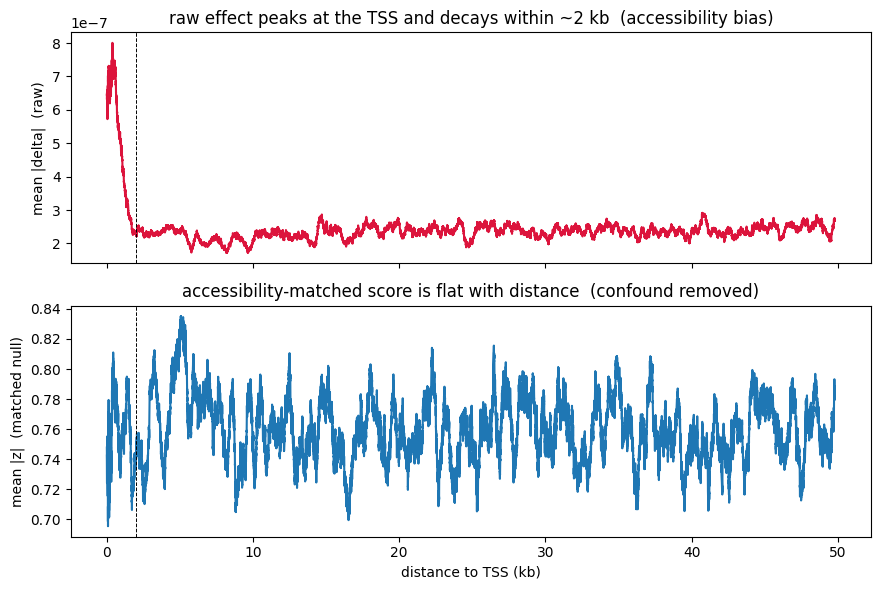

In [10]:
tss = io.tss_from_gtf(GTF).set_index('gene')['tss']
dd = df[df['gene'].isin(tss.index)].copy()
dd['absdist_kb'] = (((dd['peak_start'] + dd['peak_end']) // 2 - tss.loc[dd['gene']].values) / 1e3).abs()
dd = dd[dd['absdist_kb'] <= 50].sort_values('absdist_kb')

W = 1000                                                    # rolling window (pairs), like Fig 6B
x = dd['absdist_kb'].rolling(W, center=True).mean()
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
axes[0].plot(x, dd['delta'].abs().rolling(W, center=True).mean(), color='crimson')
axes[0].set_ylabel('mean |delta|  (raw)')
axes[0].set_title('raw effect peaks at the TSS and decays within ~2 kb  (accessibility bias)')
axes[1].plot(x, dd['zscore'].abs().rolling(W, center=True).mean(), color='C0')
axes[1].set_ylabel('mean |z|  (matched null)')
axes[1].set_title('accessibility-matched score is flat with distance  (confound removed)')
for ax in axes:
    ax.axvline(2, color='k', ls='--', lw=0.7)
axes[1].set_xlabel('distance to TSS (kb)')
plt.tight_layout(); plt.show()


## Step 7 — Locus view of a marker gene

Candidate peaks of a CD14 monocyte marker (auto-picked as the best-linked marker present) by distance from its TSS vs `score`. Star = top peak.

In this CD14 example, the top peak (star, ≈−10 kb) overlaps a fine-mapped monocyte eQTL (Blueprint CD14, PIP 0.59) — a genetically-supported distal element, not a promoter.


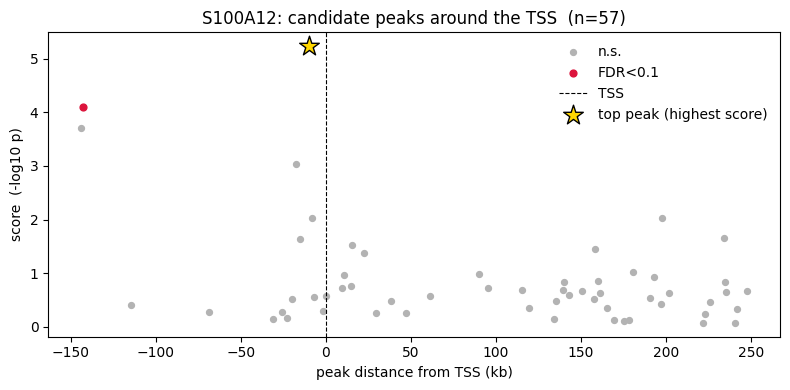

In [11]:
tss = io.tss_from_gtf(GTF).set_index('gene')['tss']
markers = ['CTSS', 'S100A8', 'S100A9', 'S100A12', 'S100A6', 'LYZ', 'FCN1', 'VCAN', 'FCGR3A', 'CD14']
present = [m for m in markers if m in set(df['gene']) and m in tss.index]
feature_gene = (max(present, key=lambda m: df.loc[df['gene'] == m, 'score'].max())
                if present else df.loc[df['score'].idxmax(), 'gene'])
g = df[df['gene'] == feature_gene].copy()
g['peak_center'] = (g['peak_start'] + g['peak_end']) / 2
g['kb_from_tss'] = (g['peak_center'] - tss[feature_gene]) / 1e3

sig_g = g['fdr'] < 0.1
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(g.loc[~sig_g, 'kb_from_tss'], g.loc[~sig_g, 'score'], s=18, c='0.7', label='n.s.')
ax.scatter(g.loc[sig_g,  'kb_from_tss'], g.loc[sig_g,  'score'], s=24, c='crimson', label='FDR<0.1')
ax.axvline(0, color='k', lw=0.8, ls='--', label='TSS')
top = g.loc[g['score'].idxmax()]
ax.scatter([top['kb_from_tss']], [top['score']], marker='*', s=220, c='gold', edgecolor='k',
           zorder=5, label='top peak (highest score)')
ax.set_xlabel('peak distance from TSS (kb)'); ax.set_ylabel('score  (-log10 p)')
ax.set_title(f'{feature_gene}: candidate peaks around the TSS  (n={len(g)})')
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## Step 8 — Per-cell heatmap for the marker gene

`compute_cell_deltas` gives the per-cell delta for one gene. Rows are the cells where the gene is **detected** (silencing an unexpressed gene gives no signal) — this matches multiDGD's own `gene2peak`, which restricts to expressing cells. Rows are ordered by the focal gene's own expression (highest on top). Columns are the gene's candidate peaks placed at their **true distance from the TSS** — tile width matches genomic spacing, like the multiDGD `gene2peak` tutorial. The dashed line marks the TSS; `*` marks the top peak.


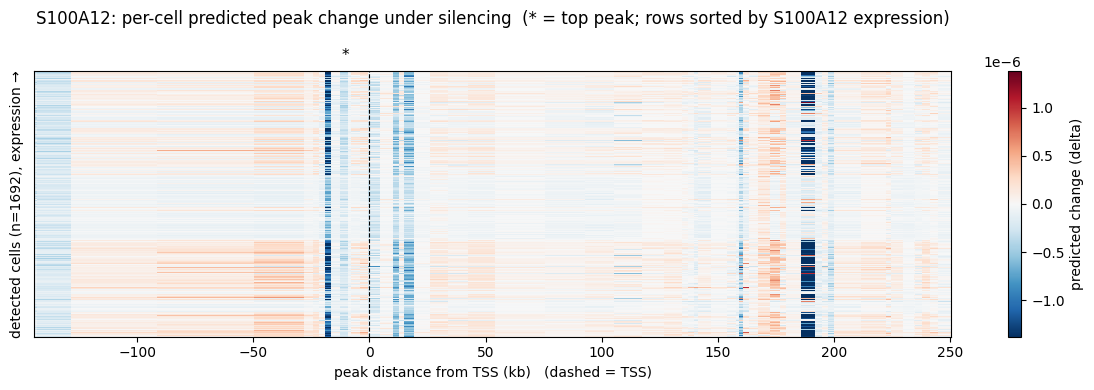

In [12]:
tg = df[df['gene'] == feature_gene].sort_values('peak_start')
target_peaks = tg['peak'].tolist()
resp_cols = [peak_col[p] for p in target_peaks]

delta_cells, cell_idx = compute_cell_deltas(
    model, feature_gene, silenced_index, resp_cols, 'gene2peak', cell_batch=8192)

# true distance of each candidate peak from the TSS (kb); peaks already position-sorted
kb = ((tg['peak_start'].values + tg['peak_end'].values) / 2 - tss[feature_gene]) / 1e3
top_kb = kb[target_peaks.index(tg.loc[tg['score'].idxmax(), 'peak'])]

# rows: cells by focal-gene expression, lowest at bottom -> highest on top
import scipy.sparse as _sp
_col = adata[:, feature_gene].X
gene_expr = (_col.toarray() if _sp.issparse(_col) else np.asarray(_col)).ravel()[cell_idx]
M = delta_cells[np.argsort(gene_expr)]

# column edges at peak-position midpoints -> tile width matches genomic spacing (true distance)
edges = np.empty(len(kb) + 1)
edges[1:-1] = (kb[:-1] + kb[1:]) / 2
edges[0], edges[-1] = kb[0] - (kb[1] - kb[0]) / 2, kb[-1] + (kb[-1] - kb[-2]) / 2
vmax = np.nanpercentile(np.abs(M), 99)

fig, ax = plt.subplots(figsize=(12, 4))
pc = ax.pcolormesh(edges, np.arange(M.shape[0] + 1), M, cmap='RdBu_r', vmin=-vmax, vmax=vmax)
ax.axvline(0, color='k', lw=0.8, ls='--')                      # TSS
ax.annotate('*', xy=(top_kb, M.shape[0]), xytext=(0, 6), textcoords='offset points',
            ha='center', va='bottom', fontsize=11, annotation_clip=False)
fig.colorbar(pc, ax=ax, label='predicted change (delta)')
ax.set_yticks([])
ax.set_xlabel('peak distance from TSS (kb)   (dashed = TSS)')
ax.set_ylabel(f'detected cells (n={len(cell_idx)}), expression →')
ax.set_title(f'{feature_gene}: per-cell predicted peak change under silencing  '
             f'(* = top peak; rows sorted by {feature_gene} expression)', pad=34)
plt.tight_layout(); plt.show()


This run uses the accessibility-matched null (`--bg matched`, the default). For the random-distal null (benchmark parity) or the reverse direction, re-score with `--bg random` or `--direction peak2gene`. Column definitions: [../README.md](../README.md#output).